# Benchmarking Steane quantum error correction

Steane-type quantum error correction (QEC) entangles a data code block with a freshly prepared ancilla code block through a transversal CNOT, and measure out one of the blocks to extract syndrome information.
This notebook uses the Steane-swap variant of this gadget, shown in Figure 4d of [arXiv:2603.04584](https://arxiv.org/abs/2603.04584), which performs a one-bit teleportation of the logical state onto the fresh code block and measures out the old block.

One QEC cycle consists of an X-correction cycle followed by a Z-correction cycle.
Together, these two cycles are equivalent to Knill QEC with its two transversal CNOTs applied in sequence rather than in parallel, so at most two code blocks are in use at any time.

## Setup

Run the next cell once in a fresh notebook environment.
IPython's `%pip` magic installs into the active kernel, so the following imports use the same environment.

In [1]:
%%capture
%pip install qldpc matplotlib

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import sinter
import stim

from qldpc import circuits, codes, decoders
from qldpc.objects import Pauli

NUM_WORKERS = max(1, min(4, (os.cpu_count() or 1) - 1))

## Fresh code blocks

Each cycle prepares a fresh code block with the flagged Steane-state preparation in Figure 1c of [Goto (2016)](https://www.nature.com/articles/srep19578).
The flag qubit catches single faults that would otherwise leave a high-weight error on the prepared block.
In practice, a fresh block is prepared by repeat-until-success: whenever its flag fires, the block is prepared again before it interacts with the data, so the data block is only ever entangled with blocks that passed their flag check.
Applying transversal Hadamards to the seven data qubits of the logical-zero preparation gives the matching logical-plus preparation, while the eighth (flag) qubit is not transformed.
The preparation begins with a reset so that it can reuse qubits that were measured in an earlier cycle.

In [3]:
code = codes.SteaneCode()

# |0> state prep circuit
zero_prep_circuit = stim.Circuit("""
    R 0 1 2 3 4 5 6 7
    # non-fault-tolerant state preparation
    H 0 2 4
    CX 0 3 2 1 4 5
    CX 0 1 2 6 4 3
    CX 2 5 3 6
    # flag errors in a logical Z representative
    H 7
    CZ 7 1 7 3 7 5
    MX 7
    DETECTOR rec[-1]  # repeat-until-success flag
""")

# |+> state prep circuit
plus_prep_circuit = zero_prep_circuit.copy()
plus_prep_circuit.append("H", range(len(code)))

## One Steane-swap cycle

An X-correction cycle prepares a fresh block in $|+_L\rangle$, applies a transversal CNOT from the fresh block onto the data block, and measures the data block in the Z basis.
Physical X errors on the data block do not propagate to the fresh block.
They instead flip Z-basis measurement outcomes, so every Z-type stabilizer of the measured block defines a detector.
The measured logical Z operator determines a logical X correction on the fresh block, which is tracked in software by including the logical measurement outcome in the Z-type logical observable.

A Z-correction cycle exchanges the roles of X and Z: the fresh block is prepared in $|0_L\rangle$ and is the target of the transversal CNOT, and the data block is measured in the X basis.

In [4]:
def get_steane_swap_cycle(
    basis: Pauli, old_block: circuits.QubitIDs, new_block: circuits.QubitIDs
) -> tuple[stim.Circuit, circuits.DetectorRecord]:
    """Teleport the logical state of old_block onto new_block by measuring old_block in a basis.

    A Z-basis measurement of old_block detects X errors; an X-basis measurement detects Z errors.

    Returns:
        stim.Circuit: The circuit for one Steane-swap cycle.
        circuits.DetectorRecord: A record of the flag and stabilizer detectors in the circuit.
    """
    # prepare a fresh code block, and identify the control and target of a transversal CNOT
    if basis is Pauli.Z:
        prep_circuit, control, target = plus_prep_circuit, new_block, old_block
    else:
        prep_circuit, control, target = zero_prep_circuit, old_block, new_block
    circuit = circuits.with_remapped_qubits(prep_circuit, new_block.data + new_block.ancilla)
    det_record = circuits.DetectorRecord({"flags": range(circuit.num_detectors)})

    # teleport the logical state onto the fresh block, measuring out the old block
    circuit.append("CX", [qubit for pair in zip(control.data, target.data) for qubit in pair])
    circuit.append(f"M{basis}", old_block.data)

    # detectors for the basis-type stabilizers, defined on the last len(code) measurements
    stabilizer_ops = code.get_stabilizer_ops(basis)
    for op_vec in stabilizer_ops:
        targets = [stim.target_rec(qubit - len(code)) for qubit in np.flatnonzero(op_vec)]
        circuit.append("DETECTOR", targets)
    det_record.append({basis: range(len(stabilizer_ops))})

    # Logical measurement outcomes determine a Pauli-frame correction to the fresh block, so they
    # are included in the basis-type logical observables.  X-type observables are numbered from 0
    # to code.dimension-1, while Z-type observables are numbered from code.dimension to
    # 2*code.dimension-1.
    circuit += circuits.get_observables(
        code,
        basis=basis,
        on_measurements=True,
        observable_indices=range(code.dimension * int(basis), code.dimension * (int(basis) + 1)),
    )
    return circuit, det_record

## Assemble a QEC cycle

The input logical qubit starts on block 0, where it is noiselessly entangled with an ideal reference qubit.
As in the combined-basis memory notebook, this reference qubit is a simulation device that lets one circuit track both X-type and Z-type logical errors.
The X-correction cycle teleports the logical state from block 0 onto block 1, and the Z-correction cycle teleports it back onto the reset qubits of block 0.

Finally, every stabilizer of block 0 is measured without adding readout noise.
A -1 result then reveals a residual error on that block at the end of the QEC cycle.
The logical operators of block 0 complete the comparison between the output state and the input state.

In [5]:
# Each code block has len(code) data qubits and one flag qubit.  Block 0 additionally has one
# ideal reference qubit for each logical qubit of the code.
qubit_ids_0 = circuits.QubitIDs(len(code), ancilla=1, reference=code.dimension)
qubit_ids_1 = circuits.QubitIDs(len(code), ancilla=1).shift(qubit_ids_0.max() + 1)

# noiselessly entangle block 0 with its reference qubits, and annotate its logical observables
circuit = circuits.get_logical_bell_prep(code, qubit_ids_0.data, qubit_ids_0.reference)
circuit += circuits.get_observables(code, qubit_ids_0.data)
det_record = circuits.DetectorRecord()

# apply an X-correction cycle, followed by a Z-correction cycle
for basis, old_block, new_block in [
    (Pauli.Z, qubit_ids_0, qubit_ids_1),
    (Pauli.X, qubit_ids_1, qubit_ids_0),
]:
    cycle_circuit, cycle_det_record = get_steane_swap_cycle(basis, old_block, new_block)
    circuit += cycle_circuit
    det_record += cycle_det_record

# append final (noiseless) stabilizer and observable readout
stabilizer_ops = code.get_stabilizer_ops()
circuit += circuits.as_noiseless_circuit(
    circuits.get_pauli_product_measurements(stabilizer_ops, qubit_ids_0.data)
)
for meas_index in range(-len(stabilizer_ops), 0):
    circuit.append("DETECTOR", [stim.target_rec(meas_index)])
det_record.append({"final": range(len(stabilizer_ops))})
circuit += circuits.get_observables(code, qubit_ids_0.data)

## Add noise and decode

Every operation outside the noiseless input preparation and final readout receives depolarizing noise.
Post-selecting on the flag detectors models the preparation of fresh blocks via repeat-until-success, and a lookup-table decoder predicts logical-observable flips.
With `max_weight=2`, the lookup table corrects every single fault, as well as many pairs of faults, such as an X-type fault caught by the first cycle together with a Z-type fault caught by the second.

The plotted logical error rate is the probability that the decoder mispredicts a logical observable after one QEC cycle.
The shaded band contains rates whose binomial likelihood is within a factor of 1,000 of the best fit.

In [6]:
error_rates = np.logspace(-4, -2, 5)
sinter_decoder = decoders.SinterDecoder(decoder=decoders.lookup(max_weight=2))

# post-select on flags to model repeat-until-success preparation of fresh blocks
postselection_mask = np.zeros(circuit.num_detectors, dtype=np.uint8)
postselection_mask[det_record.get_events("flags")] = 1

# build sinter tasks to perform our simulations
tasks = [
    sinter.Task(
        circuit=circuits.DepolarizingNoiseModel(error_rate).noisy_circuit(circuit),
        postselection_mask=np.packbits(postselection_mask, bitorder="little"),
        json_metadata={"p": error_rate},
    )
    for error_rate in error_rates
]

# run simulations and collect statistics on error rates
stats = sinter.collect(
    tasks=tasks,
    decoders=["custom"],
    custom_decoders={"custom": sinter_decoder},
    num_workers=NUM_WORKERS,
    max_shots=1_000_000,
    max_errors=100,
)

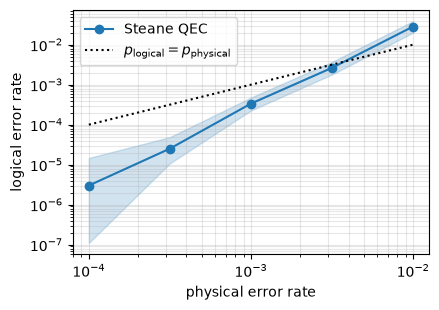

In [7]:
figure, axis = plt.subplots(figsize=(4.5, 3.2))
sinter.plot_error_rate(
    ax=axis,
    stats=stats,
    x_func=lambda stat: stat.json_metadata["p"],
    plot_args_func=lambda _index, _curve_id: {"marker": "o", "label": "Steane QEC"},
)
axis.plot(
    error_rates,
    error_rates,
    color="black",
    linestyle=":",
    label=r"$p_{\mathrm{logical}}=p_{\mathrm{physical}}$",
)
axis.set_xlabel("physical error rate")
axis.set_ylabel("logical error rate")
axis.loglog()
axis.grid(which="both", alpha=0.3)
axis.legend(loc="best")
figure.tight_layout()
plt.show()